In [1]:
from pathlib import Path
import os

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

os.chdir(project_root)

print("Current working directory:")
print(os.getcwd())

Current working directory:
/home/anshul/crop-disease-detection


In [2]:
import json
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("TensorFlow version:", tf.__version__)


I0000 00:00:1795626876.473134   63793 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795626876.519612   63793 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795626877.530138   63793 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


In [3]:
model = keras.models.load_model("models/best_baseline_model.keras")

print("Best baseline model loaded successfully.")
model.summary()

I0000 00:00:1795626902.483629   63793 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1713 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Best baseline model loaded successfully.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,391,924 (5.31 MB)

 Trainable params: 463,974 (1.77 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 927,950 (3.54 MB)

In [4]:
valid_data = tf.keras.utils.image_dataset_from_directory(
    "data/valid",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = valid_data.class_names

AUTOTUNE = tf.data.AUTOTUNE

def normalize(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

valid_data = valid_data.map(
    normalize,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("Number of classes:", len(class_names))
print("Validation data ready.")

Found 17572 files belonging to 38 classes.
Number of classes: 38
Validation data ready.


In [5]:
y_true = []
y_pred = []
y_pred_probs = []

for images, labels in valid_data:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))
    y_pred_probs.extend(predictions)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_pred_probs = np.array(y_pred_probs)

print("True labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)
print("Prediction probabilities shape:", y_pred_probs.shape)

I0000 00:00:1795627020.414680   64031 service.cc:153] XLA service 0x7237d402e5d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795627020.414718   64031 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795627020.421572   64031 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795627020.476177   64031 cuda_dnn.cc:461] Loaded cuDNN version 92801
I0000 00:00:1795627022.393708   64031 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1795627024.527022   64031 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most

True labels shape: (17572,)
Predicted labels shape: (17572,)
Prediction probabilities shape: (17572, 38)


In [6]:
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="weighted")
recall = recall_score(y_true, y_pred, average="weighted")
f1 = f1_score(y_true, y_pred, average="weighted")

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Accuracy: 0.9856020942408377
Precision: 0.9857577292859131
Recall: 0.9856020942408377
F1-score: 0.9855865833423958


In [7]:
os.makedirs("results", exist_ok=True)

baseline_evaluation = {
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1)
}

with open("results/baseline_evaluation.json", "w") as f:
    json.dump(baseline_evaluation, f, indent=4)

print("Evaluation results saved to results/baseline_evaluation.json")
print(baseline_evaluation)

Evaluation results saved to results/baseline_evaluation.json
{'accuracy': 0.9856020942408377, 'precision': 0.9857577292859131, 'recall': 0.9856020942408377, 'f1_score': 0.9855865833423958}


In [8]:
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

with open("results/baseline_classification_report.txt", "w") as f:
    f.write(report)

print("Classification report saved.")

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9940    0.9821    0.9880       504
                                 Apple___Black_rot     0.9940    0.9940    0.9940       497
                          Apple___Cedar_apple_rust     0.9954    0.9795    0.9874       440
                                   Apple___healthy     0.9880    0.9880    0.9880       502
                               Blueberry___healthy     0.9826    0.9956    0.9891       454
          Cherry_(including_sour)___Powdery_mildew     0.9929    0.9952    0.9941       421
                 Cherry_(including_sour)___healthy     0.9892    1.0000    0.9945       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9438    0.9829    0.9630       410
                       Corn_(maize)___Common_rust_     0.9979    0.9979    0.9979       477
               Corn_(maize)___Northern_Leaf_Blight     0.9803    0.9371    0.95

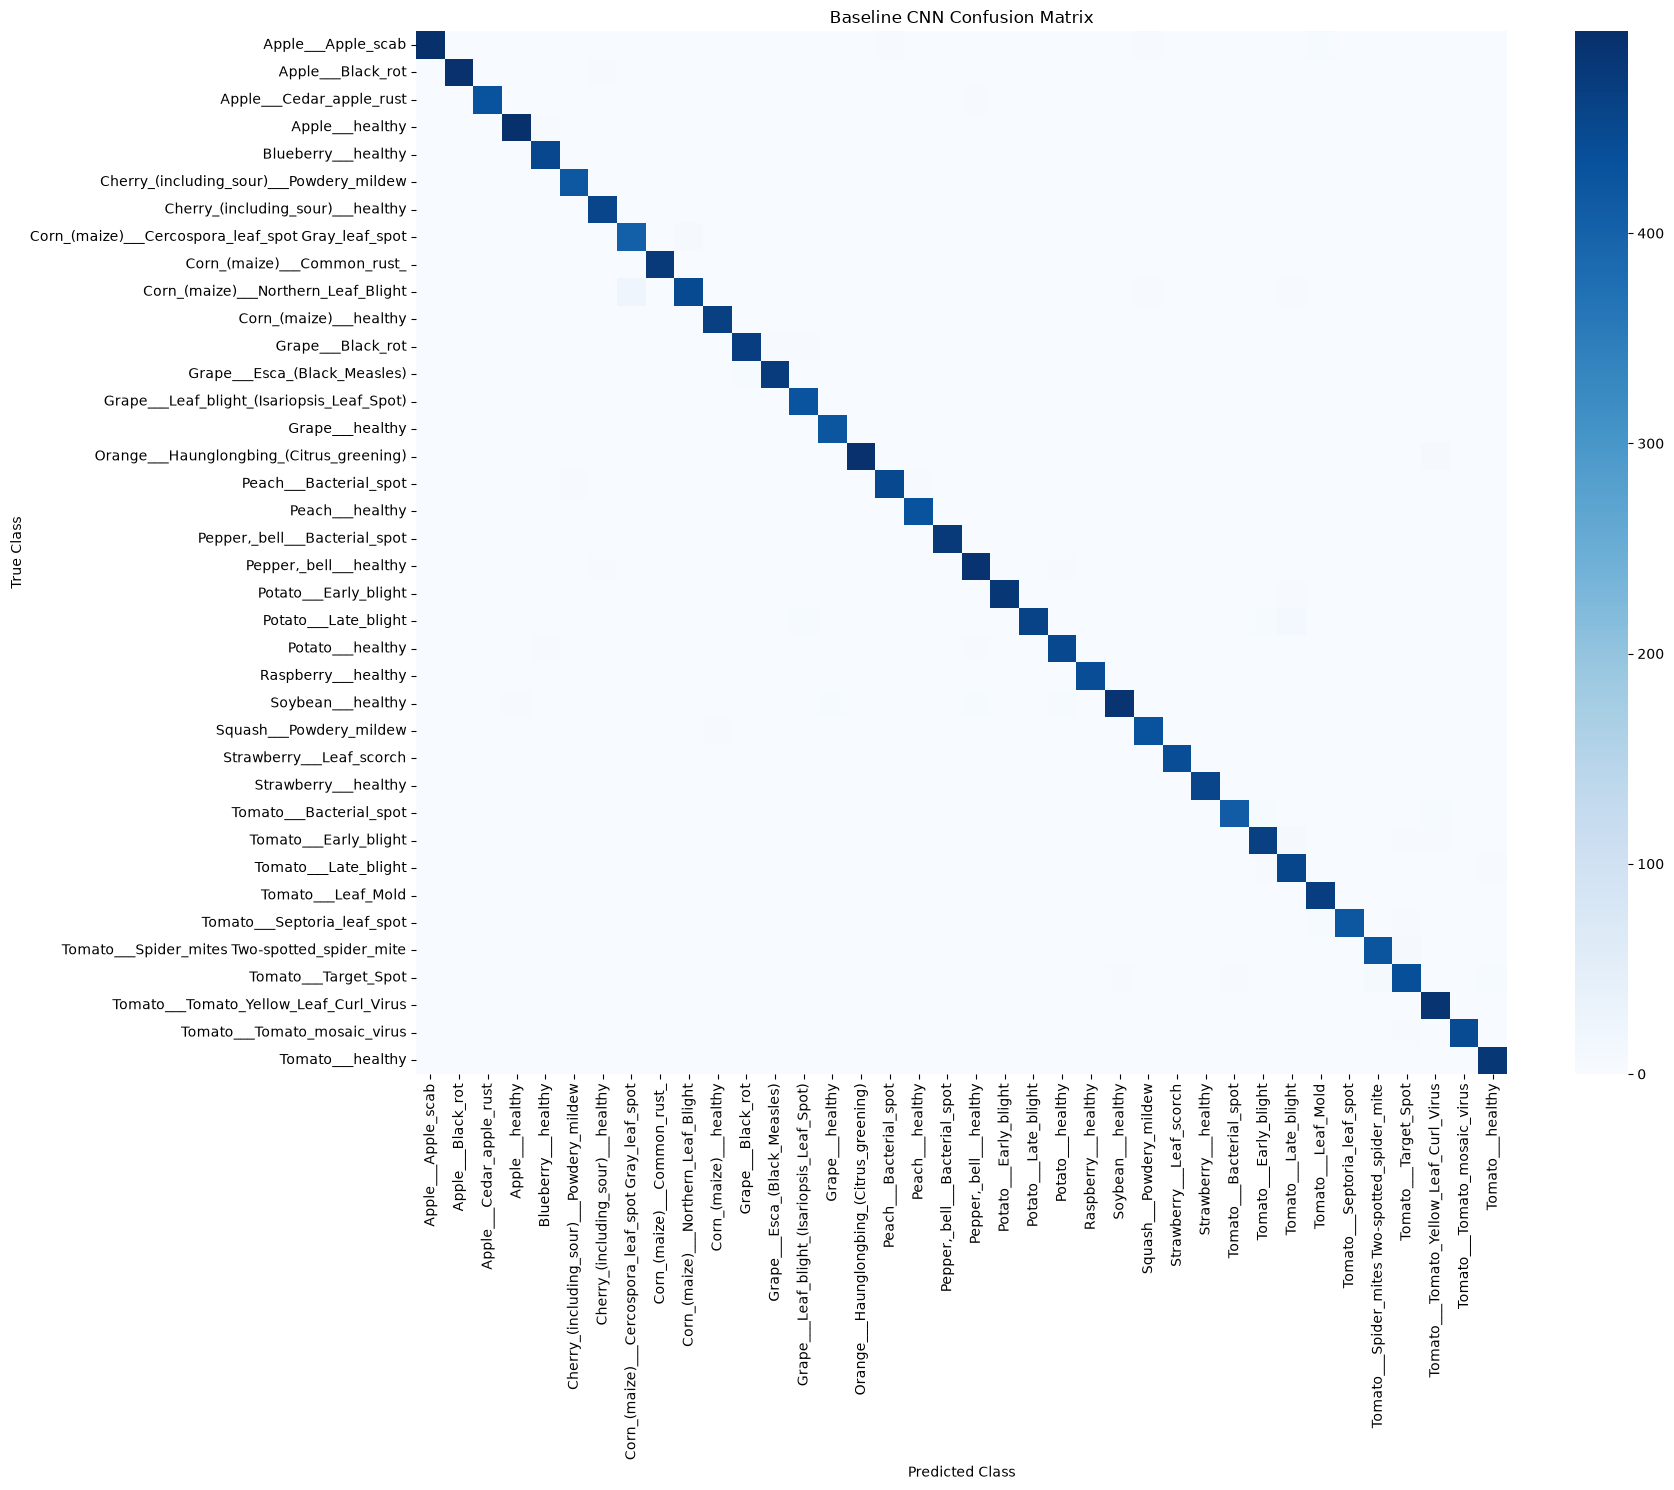

In [9]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(18, 15))
sns.heatmap(
    cm,
    annot=False,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Baseline CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

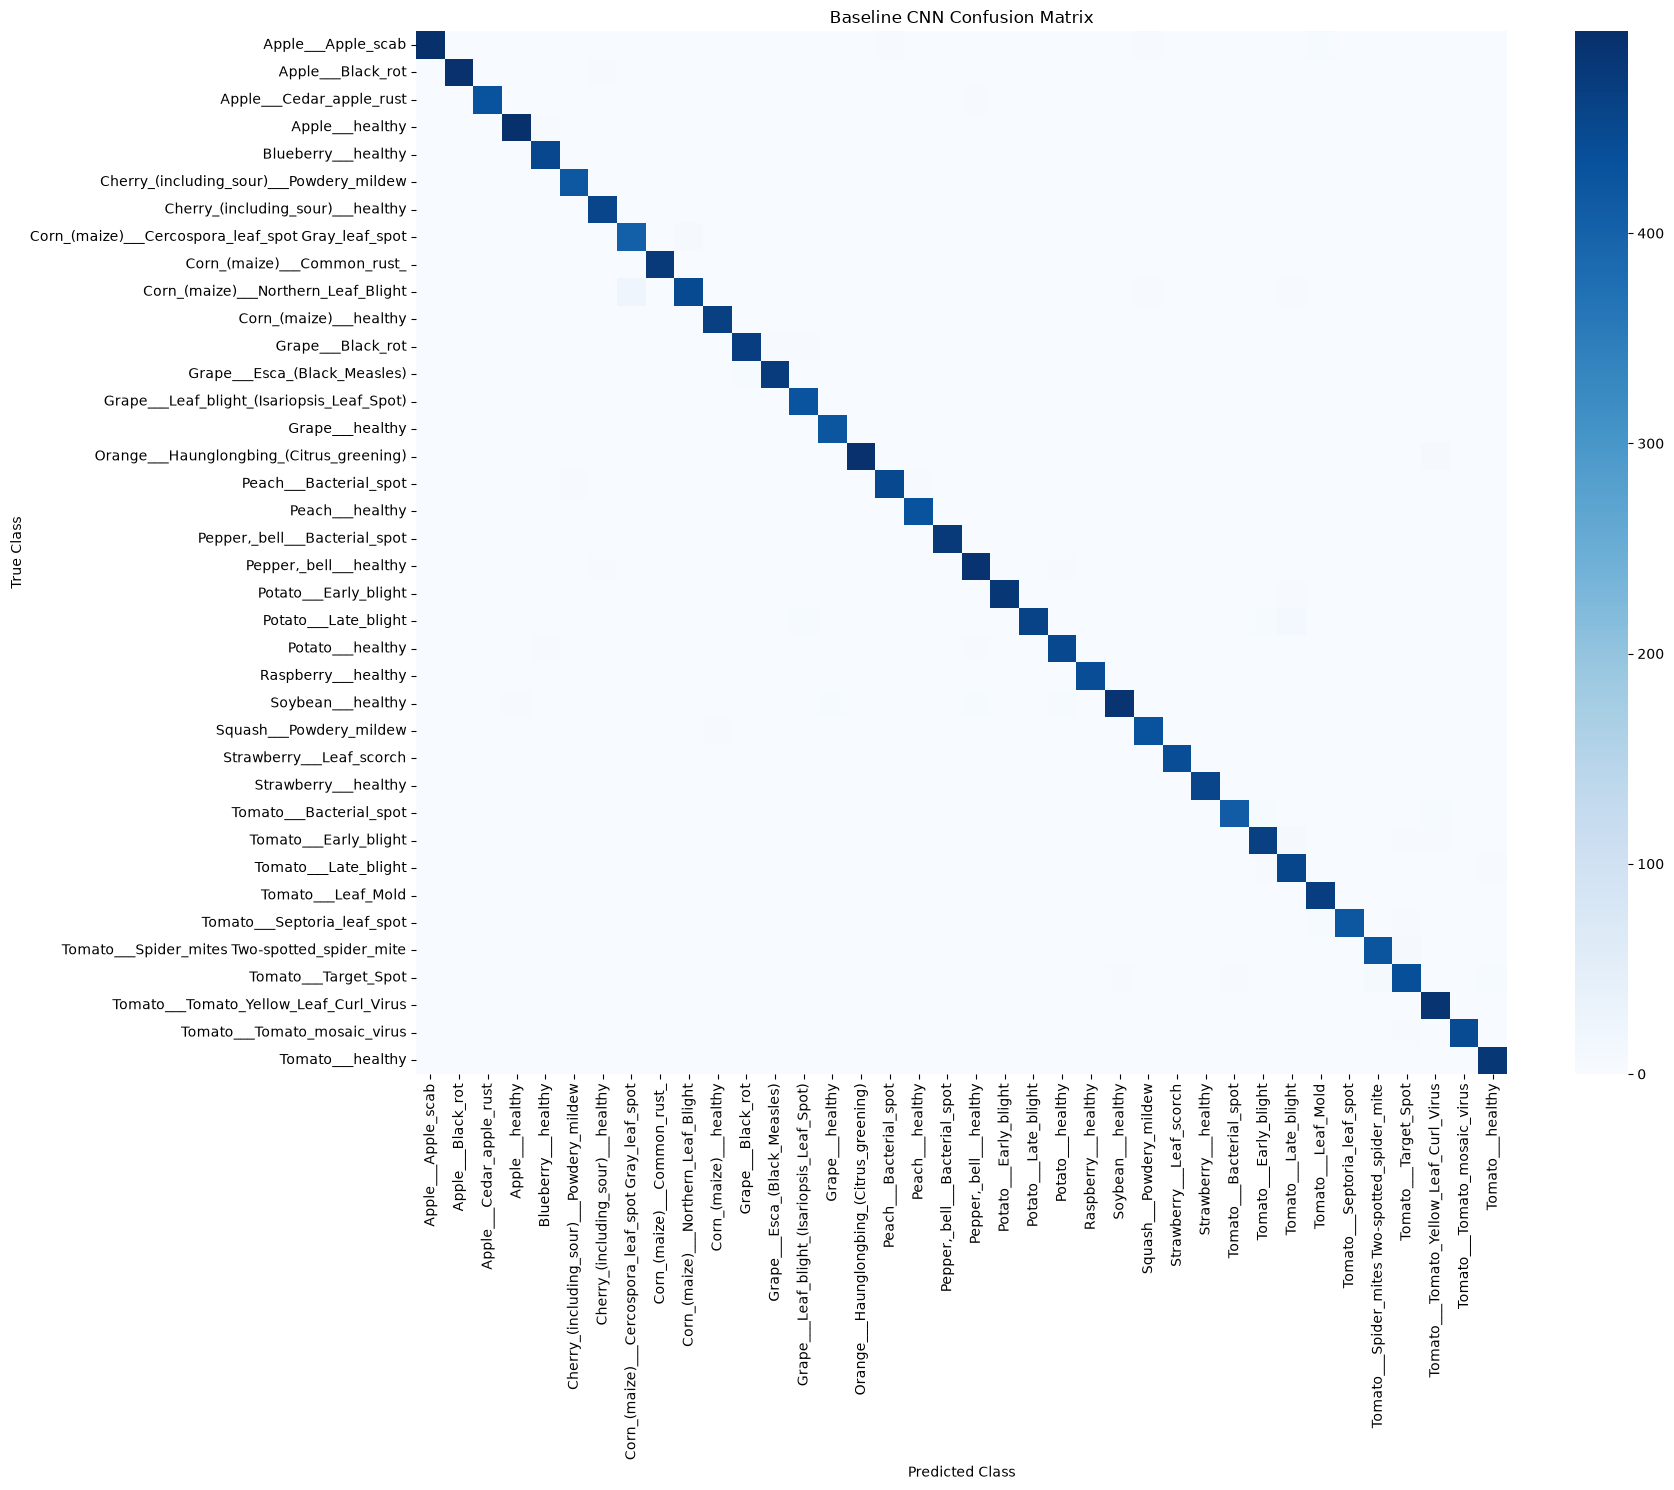

Confusion matrix saved to results/baseline_confusion_matrix.png


In [10]:
plt.figure(figsize=(18, 15))
sns.heatmap(
    cm,
    annot=False,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Baseline CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("results/baseline_confusion_matrix.png", dpi=300)
plt.show()

print("Confusion matrix saved to results/baseline_confusion_matrix.png")